In [1]:
#!conda install -c conda-forge camb --y
#!conda install -c conda-forge namaster --y

In [3]:
# ## MATPLOTLIB SETTINGS
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import cm
font = {'weight' : 'bold','size'   : 22}
mpl.rc('font', **font)
mpl.rc('font',   size=209)  #set defaults so that the plots are readable++
mpl.rc('axes',   titlesize=20)
mpl.rc('axes',   labelsize=20)
mpl.rc('xtick',  labelsize=20)
mpl.rc('ytick',  labelsize=20)
mpl.rc('legend', fontsize =20)
mpl.rc('figure', titlesize=20)
mpl.rc('text',   usetex=True)
## FURTHER MATPLOTLIB FEATURES
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
from matplotlib.ticker import ScalarFormatter, FormatStrFormatter
from matplotlib.colors import ListedColormap
colors = ['forestgreen','navy','mediumorchid','purple','dodgerblue','crimson','black','darkorange']
my_cmap = ListedColormap(colors, name="my_cmap")
font_dict = {'family': 'serif', 'color':  None,  'weight': 'bold','size': 30}
#############################################
#BASIC SYSTEM PACKAGES
import sys,time,os,camb#, h5py
import pymaster as nmt
import numpy as np
import pandas as pd
from copy import deepcopy as dcopy
#############################################
#FURTHER BASIC PACKAGES
#from scipy.interpolate import interp1d
#############################################
#PATH TO SCRIPTS FOLDER
path =  '/data/AMARINS/LSSxHI-CODES/scripts/'
sys.path.insert(1, path)
import cross_functions_theory           as cxft
import cross_functions_theory_4forecast as c4ft
import cross_functions_simulations      as cxfs
import handling_data                    as hdata

In [4]:
z_lowz  = cxft.z_hi_survey(hi_survey='LOWZ')
z_lowz

array([0.12730615, 0.13571888, 0.14425812, 0.15292675, 0.16172771,
       0.17066408, 0.179739  , 0.18895571, 0.19831756, 0.20782802,
       0.21749064, 0.22730912, 0.23728724, 0.24742894, 0.25773827,
       0.26821942, 0.27887673, 0.28971467, 0.30073787, 0.31195113,
       0.3233594 , 0.33496781, 0.34678169, 0.35880652, 0.37104802,
       0.3835121 , 0.39620487, 0.40913269, 0.42230215, 0.4357201 ,
       0.44939362])

In [5]:
N,nch = 30, 30
dinfo = cxft.get_zeff(numin =980, numax =1260, nbands= nch, n_curves=N)
feff  = dinfo['nu_eff'][::-1]
zeff  = dinfo['zeff'][::-1]
ibins = dinfo['bins']

In [6]:
ich=20
zeff[ich-1], feff[ich-1]

(0.32, 1078.0)

In [7]:
#############################################
## DEFINITIONS
EPS = 1e-25
nu_HI   = 1420.405751768 #MHz
C_LIGHT = 299792458 / 1e3  # km/s
STERADIAN = np.radians(1/60) ** 2
#############################################
## NAMASTER SETTINGS 
DEL_L = 4
NSIDE = 256
NPIX  = 12*NSIDE*NSIDE
#LMIN,LMAX=30,400
#WAEL = (leff>=LMIN)*(leff<=LMAX)
##
b    = nmt.NmtBin.from_nside_linear(NSIDE, nlb=DEL_L)
leff = b.get_effective_ells()
feff = leff*(leff+1)/2/np.pi
##

In [8]:
path_lsst = "/data/AMARINS/LSSxHI-CODES/scripts/parameters/lsst_desc_parameters.yaml"
path_ecl  = "/data/AMARINS/LSSxHI-CODES/scripts/parameters/euclid_parameters.yaml"

In [9]:
pars_lsst = cxft.load_survey_parameters(survey_name = 'LSST', data_release='Y10', type_field='density', path_file=path_lsst)
pars_lsst['nbins'      ]=10
pars_lsst['n_tomo_bins']=10
pars_lsst['sigma_z'    ]=0.03
dNdz_lsst10 = cxft.dNdz_func(pars=pars_lsst, binning=1 ,  verbose=False, type_field=pars_lsst['field'])
################################
pars_lsst = cxft.load_survey_parameters(survey_name = 'LSST', data_release='Y10', type_field='density', path_file=path_lsst)
pars_lsst['nbins'      ]=40
pars_lsst['n_tomo_bins']=40
pars_lsst['sigma_z'    ]=0.001
dNdz_lsst40 = cxft.dNdz_func(pars=pars_lsst, binning=True,  verbose=False, type_field=pars_lsst['field'], Np=5000)

/data/AMARINS/LSSxHI-CODES/images/galaxy_distribution_distcomparison.pdf


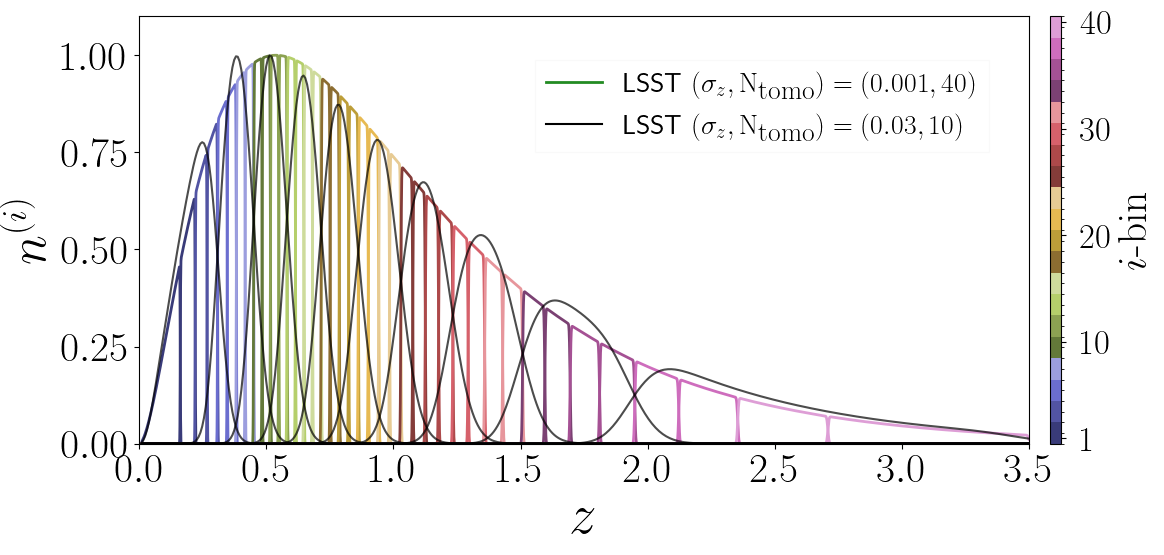

In [19]:
ncols,nrows = 1,1
fig, axes   = plt.subplots(nrows=nrows, ncols=ncols)
plt.subplots_adjust(top=1*nrows,right=(1.8)*ncols, wspace=0.02, hspace=0.25)
############################################################
nch,N  = 5, 40
c    = np.arange(1., nch + 1)
norm = mpl.colors.BoundaryNorm(np.arange(1, N+2,1),N)
cmap2 = plt.get_cmap("tab20b"    , N+1)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap2)
sm.set_array([])
############################################################
ax1 = axes#[0]
for i in range(40): ax1.plot(dNdz_lsst40[ 'z'], dNdz_lsst40[ 'dNdz'][i,:]/dNdz_lsst40[ 'dNdz'][:,:].max(), c=cmap2(i), lw=2, ls='solid' , alpha=1.00)
for i in range(10): ax1.plot(dNdz_lsst10[ 'z'], dNdz_lsst10[ 'dNdz'][i,:]/dNdz_lsst10[ 'dNdz'][:,:].max(), c='black', lw=1.5, ls='solid' , alpha=0.70)
############################################################
ax1.set_xlabel(r"$z$"      , fontsize =40)
ax1.set_ylabel(r"$n^{(i)}$", fontsize =37)    
ax1.tick_params(axis='both', which='major' , labelsize=30)
ax1.set_xlim(0,3.5)
ax1.set_ylim(0,1.1)
###########################################################
#cticks = np.arange(1, N+1,1)#np.linspace(1, len(c)+1, len(c), dtype=np.int8)
cticks=np.array([1,10,20,30,40])#np.linspace(1,N+1,5)
cbar=plt.colorbar(sm, ax=ax1,pad=0.02, aspect=40, ticks=cticks+0.5)
cbar.ax.set_yticklabels([r'${:.0f}$'.format(c) for c in cticks])
cbar.set_label(label=r'$i\textrm{-bin}$',size=30)#,weight='bold')
cticks = np.array([r'${}$'.format(i) for i in cticks])
cbar.ax.tick_params(labelsize=25, pad=10)
###########################################################
custom_lines = [Line2D([], [], color='forestgreen'  , linewidth=2, linestyle='solid', alpha=1.00),
                #Line2D([], [], color=cmap2(1)  , linewidth=2, linestyle='solid', alpha=0.70),
                Line2D([], [], color='black'  , linewidth=1.5, linestyle='solid', alpha=1.00),]
legend = ax1.legend(custom_lines, [r'LSST $(\sigma_z,\textrm{N}_{\textrm{tomo}})=(0.001, 40)$', 
                                   r'LSST $(\sigma_z,\textrm{N}_{\textrm{tomo}})=(0.03, 10)$', 
                                   #r'LSST $(\sigma_z,\textrm{N}_{\textrm{tomo}})=(0.03, 5)$'
                                  ],#title='LSST',
                   ncols=1, fontsize=20, loc='lower center',framealpha=0.1, fancybox=False,
                   bbox_to_anchor=(0.70, 0.65),  shadow=False,)#edgecolor='lightblue', 
plt.setp(legend.get_title(), fontsize='24', color='black', fontweight='bold');
###########################################################
pathname = "/data/AMARINS/LSSxHI-CODES/images/{}_{}_{}.pdf".format( 'galaxy',"distribution", "distcomparison" )
plt.savefig(pathname, dpi=100, bbox_inches='tight');
print(pathname)
###########################################################
plt.show();

In [29]:
## CAMB
path_dir = '/data/AMARINS//LSSxHI-DATA/forecast/input/'
file_yaml = 'generating_APS_theory_{b}x{c}.yaml'.format(b=4,c=18) 
filename_cl_yaml = os.path.join(path_dir,file_yaml)
p_loaded    = c4ft.load_yaml_fileformat(filename_cl_yaml, verbose=0)
params_APS  = dcopy(p_loaded["APS"])
params      = dcopy(p_loaded["cosmology"]) 
######################################################################
params['H0'     ] = 67.4
params['ombh2'  ] = 0.022
params['omch2'  ] = 0.122
params['mnu'    ] = 0.06
params['w0'     ] = -1
params['wa'     ] = 0
params['As'     ] = 2.0e-9
params['ns'     ] = 0.965
params['z'      ] = np.logspace(np.log10(1e-5),np.log10(5), 256)
params['kmax'   ] = 100
params['minkh'  ] = 1e-5
params['maxkh'  ] = 100
params['npoints'] = 1000000
params['DE_model'       ] = 'DarkEnergyPPF'
params['Pk_nonlinear'   ] = True
params['halofit_version'] = 'takahashi'
######################################################################
cpars = camb.set_params(halofit_version=params['halofit_version'])
cpars.set_cosmology(H0=params['H0'], ombh2=params['ombh2'], omch2=params['omch2'])
cpars.InitPower.set_params(ns=params['ns'])
cpars.set_matter_power(redshifts=params['z'], kmax=params['kmax'], silent=1)
cresults  = camb.get_results(cpars)
pk_interp = camb.get_matter_power_interpolator(cpars, 
                                               nonlinear=params['halofit_version'], hubble_units=False, k_hunit=False, 
                                               kmax=params['kmax'], zmax=params['z'][-1])
print('Done!')

bins_f1f2 = {
                1: np.array([8,9        ]),
                #2: np.array([11,12,13,14]),
                2: np.array([12,13,14]),        
                3: np.array([15,16,17,18]),
                4: np.array([19,20,21   ]),
                5: np.array([22,23,24   ]),
                6: np.array([25,26      ]),
                7: np.array([28,29      ])    
                }

Done!


In [30]:
pars_lsst = cxft.load_survey_parameters(survey_name = 'LSST', data_release='Y10', type_field='density', path_file=path_lsst)
pars_lsst['nbins'      ]=10
pars_lsst['n_tomo_bins']=10
pars_lsst['sigma_z'    ]=0.03
W_f2_10 = cxft.kernel_galaxy_clustering_dict(camb_params=cpars, camb_results=cresults, 
                                              pars=pars_lsst,
                                              #ibin = params_APS['field_2_params']['bin_to_use'],
                                              include_rsd=params_APS['field_2_params']['include_rsd'], 
                                              include_mb = params_APS['field_2_params']['include_mb'] , growth_rate_f=None, 
                                              bias_model = params_APS['field_2_params']['bias_model'], 
                                              bias_value = params_APS['field_2_params']['bias_value'],
                                              path_to_bias_file=params_APS['field_2_params']['path_to_bias_file'],
                                              mb_model   = params_APS['field_2_params']['slope_s_model'], 
                                              mb_alpha_value = params_APS['field_2_params']['slope_s_value'], 
                                              #path_to_mb_file=params_APS['field_2_params']['path_to_slope_s_file'], 
                                              mu_rsd=params_APS['field_2_params']['mu_rsd'], Np=500)  

pars_lsst = cxft.load_survey_parameters(survey_name = 'LSST', data_release='Y10', type_field='density', path_file=path_lsst)
pars_lsst['nbins'      ]=40
pars_lsst['n_tomo_bins']=40
pars_lsst['sigma_z'    ]=0.001
W_f2_40 = cxft.kernel_galaxy_clustering_dict(camb_params=cpars, camb_results=cresults, 
                                              pars=pars_lsst,
                                              #ibin = params_APS['field_2_params']['bin_to_use'],
                                              include_rsd=params_APS['field_2_params']['include_rsd'], 
                                              include_mb = params_APS['field_2_params']['include_mb'] , growth_rate_f=None, 
                                              bias_model = params_APS['field_2_params']['bias_model'], 
                                              bias_value = params_APS['field_2_params']['bias_value'],
                                              path_to_bias_file=params_APS['field_2_params']['path_to_bias_file'],
                                              mb_model   = params_APS['field_2_params']['slope_s_model'], 
                                              mb_alpha_value = params_APS['field_2_params']['slope_s_value'], 
                                              #path_to_mb_file=params_APS['field_2_params']['path_to_slope_s_file'], 
                                              mu_rsd=params_APS['field_2_params']['mu_rsd'], Np=500) 
#############################################
z_lowz  = cxft.z_hi_survey(hi_survey='LOWZ')
z_highz = cxft.z_hi_survey(hi_survey='HIGHZ')

/data/AMARINS/LSSxHI-CODES/images/galaxy_kernel_comparison.png


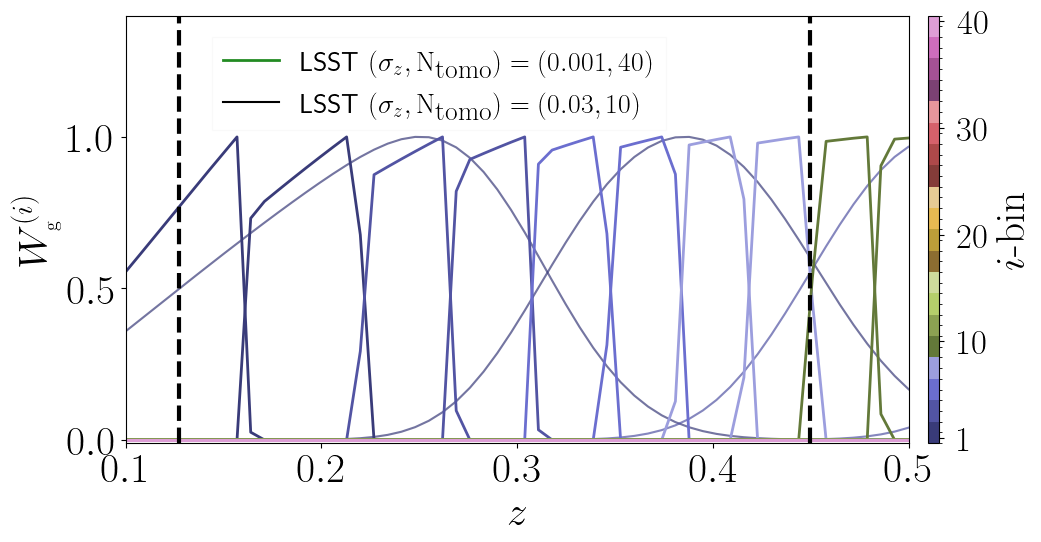

In [32]:
fig, ax1   = plt.subplots(nrows=1, ncols=1)
plt.subplots_adjust(top=1,right=1.6, wspace=0.02,)     
############################################################
n,N  = 40,40#pars_lsst['nbins'],pars_lsst['nbins']
c    = np.arange(1., n + 1)
norm = mpl.colors.BoundaryNorm(np.arange(1, N+2,1),N)
cmap = plt.get_cmap("tab20b", N+1)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
############################################################
for i in range(pars_lsst['nbins']):
    x = W_f2_40['z'][i]
    y = W_f2_40['W'][i]
    y=y/y.max()
    ax1.plot(x, y, c=cmap(i), label=None,lw=2, ls='solid' , alpha=1.00)   
    try:
        x = W_f2_10['z'][i]
        y = W_f2_10['W'][i]
        y=y/y.max()
        ax1.plot(x, y, c=cmap(i), label=None,lw=1.52, ls='solid' , alpha=0.70)   
    except:
        pass
############################################################
ax1.set_xlabel(r"$z$"                      , fontsize =30)
ax1.set_ylabel(r"$W_{\textrm{\Large g}}^{(i)}$", fontsize =30)    
ax1.tick_params(axis='both', which='major' , labelsize=30)
ax1.set_xlim(0.1,0.5)
ax1.set_ylim(-0.01,1.4)
ax1.axvline(x=z_lowz.min(), c='black',ls='dashed', lw=3)
ax1.axvline(x=z_lowz.max(), c='black',ls='dashed', lw=3)
###########################################################
cticks = np.arange(1, N+1,1)#np.linspace(1, len(c)+1, len(c), dtype=np.int8)
cticks = np.linspace(cticks.min(), cticks.max(),5, dtype=np.int16)
cbar=fig.colorbar(sm, ax=ax1,pad=0.02, aspect=40, ticks=cticks+0.5)
cbar.set_label(label=r'$i\textrm{-bin}$',size=30)#,weight='bold')
cticks = np.array([r'${}$'.format(i) for i in cticks])
cbar.ax.set_yticklabels(cticks)
cbar.ax.tick_params(labelsize=25, pad=10)
###########################################################
custom_lines = [Line2D([], [], color='forestgreen'  , linewidth=2, linestyle='solid', alpha=1.00),
                #Line2D([], [], color=cmap2(1)  , linewidth=2, linestyle='solid', alpha=0.70),
                Line2D([], [], color='black'  , linewidth=1.5, linestyle='solid', alpha=1.00),]
legend = ax1.legend(custom_lines, [r'LSST $(\sigma_z,\textrm{N}_{\textrm{tomo}})=(0.001, 40)$', 
                                   r'LSST $(\sigma_z,\textrm{N}_{\textrm{tomo}})=(0.03, 10)$', 
                                   #r'LSST $(\sigma_z,\textrm{N}_{\textrm{tomo}})=(0.03, 5)$'
                                  ],#title='LSST',
                   ncols=1, fontsize=20, loc='lower center',framealpha=0.1, fancybox=False,
                   bbox_to_anchor=(0.40, 0.70),  shadow=False,)#edgecolor='lightblue', 
plt.setp(legend.get_title(), fontsize='24', color='black', fontweight='bold');
###########################################################
pathname = "/data/AMARINS/LSSxHI-CODES/images/{}_{}_{}.png".format( 'galaxy',"kernel", "comparison" )
#plt.savefig(pathname, dpi=100, bbox_inches='tight');
print(pathname)
###########################################################
plt.show()

In [33]:
dNdz_lsst40[ 'z'].shape

(5000,)

In [34]:
def kernel_galaxy_clustering_dict(camb_params=None  , camb_results=None, pars=None, cut_to_bin=False, #binning=True,
                                  include_rsd=False , include_mb=False , mu_rsd=0 , growth_rate_f=None, 
                                  bias_model ='SQRT', bias_value=1     , path_to_bias_file=None,
                                  mb_model   =False , mb_alpha_value=0 , path_to_mb_file=None  ,Np=500,
                                  verbose=False):
    '''
    RSD:Redshift Spatial Distortion
    MB:Magnification Bias
    mu_rsd: <k,n>=cos(theta)
    growth_rate_f: add in the future the possibility to read a file [z,f(z)]
    pars: parameters of Galaxy survey
    bias_model: constant, LSST, EUCLID, READ [to read a file]
    '''
    c_light = 299792458/1e3
    binning = True
    from scipy.interpolate import interp1d
    if verbose: timei = time.time()     
    #
    z_range  = np.linspace(pars['z_min'], pars['z_max'], Np)
    bias_gc  = get_bias_model(bias_model=bias_model, bias_value=bias_value, pars=pars, path_to_file=path_to_bias_file, z_range=z_range)
    dNdz_vec = dNdz_func(pars=pars, binning=binning,  verbose=False, type_field=pars['field'])
    #chi_z = lambda x: camb_results.comoving_radial_distance(x)    
    #fact  = lambda y: camb_results.hubble_parameter(y)/c_light
    for j in range(dNdz_vec['dNdz'].shape[0]):
        dNdz_intp = interp1d(dNdz_vec['z'], dNdz_vec['dNdz'][j,:], kind='cubic')
        #igc       = np.array([ dNdz_intp(zi)*camb_results.hubble_parameter(zi)/c_light for zi in z_range ])
        igc       = np.array([ dNdz_intp(zi)for zi in z_range ])
        igc*=bias_gc
        if not j:
            kernel_gc= dcopy(  igc   )
            zv_range = dcopy(z_range )
        else:
            kernel_gc= np.vstack(( kernel_gc, dcopy(igc)     ))
            zv_range = np.vstack((  zv_range, dcopy(z_range) ))        
    if include_rsd:
        f_vec = interp1d(camb_results.z_input, camb_results.get_fsigma8()/camb_results.get_sigma8(), kind='cubic')(z_range)
        kernel_gc+=(f_vec*mu_rsd**2)*kernel_gc
    if include_mb:
        MB = magnification_bias(camb_params=camb_params, camb_results=camb_results, pars=pars,
                                slope_s_model=mb_model, z_range=z_range,
                                binning=binning, ibin=None, Np=Np, verbose=False)
        kernel_gc+=MB
        pass    
    if verbose: print('Total processing time: {0:.2f} seg'.format(time.time()-timei))             
    return {'W':kernel_gc, 'z':zv_range}  

In [35]:
def kernel_hi_vec(camb_params=None, camb_results=None, 
                  zout=None, zrange=None, 
                  config_dict=None, use_input=False, 
                  params_interp=None, decimals=6, 
                  replace_inf2nan=True, get_interp_function=False,
                  nzext = 5000):

    from scipy.interpolate import interp1d
    from scipy import integrate
    C_LIGHT = 299792458/1e3 #km/s
    nu_HI   = 1420.405751768 #MHz
    """
    HI-KERNEL vetorized (or its interpolation)
    
    Args:
        zrange              :numpy array  : Edge redshifts of the HI IM survey  (standard value: None)
        zout                :numpy array  : redshifts to be provide the HI-kernel from  (standard value: None)    
        camb_params         :CAMB instance: CAMB parameters instance (standard value: None)
        camb_results        :CAMB instance: CAMB results instance    (standard value: None)    

        config_dict         :dict: provide the HI information such as omega_HI model, bias_HI model, ...  (standard value: None)
        params_interp       :dict: ------    (standard value: None)
        use_input           :bool: inform weather it would be used camb instabce or function from the dict params_interp  (standard value: None)
        decimals            :int:  decimal level to be calculate the redshift within the window function  (standard value: 6)
        get_interp_function :bool: to obtain the interpolation instead of   (standard value: False)
        replace_inf2nan     :bool: to replace infinity values to numpy NaN   (standard value: True)
        
    Returns:
           Window function:
               numpy array , if get_interp_function=False
               scipy interp, if get_interp_function=True
        
    Ps.:          
        If you choice to determine (fit) HI bias (bHI) and Omega HI (OHI), 
        you must to specify True for the fit_bHI (fit_OHI) parameter and to set the parameter value
        otherwise, the code will define the standard model.   
    """
    from scipy.interpolate import interp1d
    omegaHI_model = config_dict['omegaHI_model']
    biasHI_model  = config_dict['biasHI_model']
    fit_bHI       = config_dict['fit_biasHI']
    fit_OHI       = config_dict['fit_omegaHI']
    bHI           = config_dict['biasHI']
    OHI           = config_dict['omegaHI']
    
    zrange_ext = []
    for i in range(zrange[:-1].size):
        zrange_ext.append( np.linspace(zrange[i], zrange[i+1], nzext) ) ## |delta_zext|<1e-4 for zrange in [0.12,0.45]
    zrange_ext = np.array(  zrange_ext ).flatten()    
    zrange_ext = np.unique( zrange_ext )
    
    w1  = np.array([ cxft.window_2(value=np.around(iz,decimals), arr=zrange) for iz in zrange_ext ]) #selection function
    THI = c4ft.hi_brightness_temperature(camb_params=camb_params, 
                                         camb_results=camb_results, z=zrange_ext, 
                                         model=omegaHI_model, fit_OHI=fit_OHI, OHI=OHI, 
                                         use_input=use_input, params_interp=params_interp )
    if not fit_bHI or type(bHI)==type(None): 
        bHI =  c4ft.omegaHI_biasHI(model=biasHI_model,z=zrange_ext)['biasHI']
    else:
        pass
    arr = bHI*THI*w1    
    if replace_inf2nan:
        #arr = bHI*THI*w1
        arr_interp = interp1d(x=zrange_ext, y=arr, kind='cubic', fill_value=np.nan)
        arr        = arr_interp(zrange)
        #arr[np.isinf(arr)] = np.nan 
        #return arr
    else: 
        arr_interp = interp1d(x=zrange_ext, y=arr, kind='cubic')
        arr        = arr_interp(zrange)
        
    if not get_interp_function:
        if zout is None:
            return arr#bHI*THI*w1     
        else:
            return arr_interp(zout)#np.interp(zout, zrange, arr)
    else:
        
        return arr_interp#interp1d(x=zrange, y=arr, kind='cubic', fill_value=np.nan)

In [36]:
def get_Whi_z_bin(zmin=None, zmax = None, pars=None, pars_aps=None, numz=None, nzext=None):
    ###########################################
    pars_camb = c4ft.get_camb_results(pars)
    zv   = np.logspace(np.log10(zmin), np.log10(zmax), numz)                
    Whi = kernel_hi_vec(
                    zout=zv, 
                    camb_params = pars_camb["camb_params"], 
                    camb_results= pars_camb["camb_results"],
                    zrange      = pars_aps['field_1_params']['z'], 
                    config_dict = pars_aps["field_1_params"], 
                    replace_inf2nan= True, 
                    use_input      = False,
                    params_interp  = None,             
                    get_interp_function=0, 
                ) 
    return Whi, zv

def get_Whi_z_bins(hbins=[8,9], zvec = None, pars=None, pars_aps=None, numz=100, nzext=None):
    hbins = np.array(hbins)
    Whi_vec = np.zeros((hbins.size, numz))
    z_vec   = np.zeros((hbins.size, numz))    
    for i,hbin in enumerate(hbins):
        zmin  = zvec[hbin+0]
        zmax  = zvec[hbin+1] 
        Whi_vec[i], z_vec[i] = get_Whi_z_bin(zmin=zmin, zmax = zmax, pars=pars, pars_aps=pars_aps, numz=numz, nzext=nzext)
    return Whi_vec, z_vec


def plot_filter_texts(ax=None, cmap_=None, index_start=0, cweight_1='bold', cweight_2='bold', size1=20, size2=13, add_text_outline2=False, text_outline_lw=3, text_outline_fg='black'):
    if add_text_outline2: import matplotlib.patheffects as pe
    ax.text(x=0.200, y=1.12, s=r'$\mathrm{Set 1}$', 
            fontdict={'family': 'serif', 'color': 'black',  'weight': cweight_1,'size': size1})
    ax.text(x=0.245, y=1.12, s=r'$\mathrm{Set 2}$', 
            fontdict={'family': 'serif', 'color': 'black',  'weight': cweight_1,'size': size1})
    ax.text(x=0.280, y=1.12, s=r'$\mathrm{Set 3}$', 
            fontdict={'family': 'serif', 'color': 'black',  'weight': cweight_1,'size': size1})
    ax.text(x=0.321, y=1.12, s=r'$\mathrm{Set 4}$', 
            fontdict={'family': 'serif', 'color': 'black',  'weight': cweight_1,'size': size1})
    ax.text(x=0.355, y=1.12, s=r'$\mathrm{Set 5}$', 
            fontdict={'family': 'serif', 'color': 'black',  'weight': cweight_1,'size': size1})
    ax.text(x=0.387, y=1.12, s=r'$\mathrm{Set 6}$', 
            fontdict={'family': 'serif', 'color': 'black',  'weight': cweight_1,'size': size1})
    ax.text(x=0.427, y=1.12, s=r'$\mathrm{Set 7}$', 
            fontdict={'family': 'serif', 'color': 'black',  'weight': cweight_1,'size': size1})
    ###########################################################
    #### Set1
    text = ax.text(x=0.2018, y=1.03, s=r'$\mathrm{9}$', 
                   fontdict={'family': 'serif', 'color': cmap_(index_start+0),  'weight': cweight_2,'size': size2})
    if add_text_outline2: text.set_path_effects([pe.withStroke(linewidth=text_outline_lw, foreground=text_outline_fg)])
    text = ax.text(x=0.20938, y=1.03, s=r'$\mathrm{10}$', 
            fontdict={'family': 'serif', 'color': cmap_(index_start+0),  'weight': cweight_2,'size': size2})
    if add_text_outline2: text.set_path_effects([pe.withStroke(linewidth=text_outline_lw, foreground=text_outline_fg)])   
    #### Set2    
    text = ax.text(x=0.239 , y=1.03, s=r'$\mathrm{13}$', 
                   fontdict={'family': 'serif', 'color': cmap_(index_start+1),  'weight': cweight_2,'size': size2})
    if add_text_outline2: text.set_path_effects([pe.withStroke(linewidth=text_outline_lw, foreground=text_outline_fg)])                                                 
    text = ax.text(x=0.2495, y=1.03, s=r'$\mathrm{14}$', 
                   fontdict={'family': 'serif', 'color': cmap_(index_start+1),  'weight': cweight_2,'size': size2})
    if add_text_outline2: text.set_path_effects([pe.withStroke(linewidth=text_outline_lw, foreground=text_outline_fg)])                                                 
    text = ax.text(x=0.2595, y=1.03, s=r'$\mathrm{15}$', 
                   fontdict={'family': 'serif', 'color': cmap_(index_start+1),  'weight': cweight_2,'size': size2})
    if add_text_outline2: text.set_path_effects([pe.withStroke(linewidth=text_outline_lw, foreground=text_outline_fg)])                                               
    #### Set3    
    text = ax.text(x=0.271, y=1.03, s=r'$\mathrm{16}$', 
                   fontdict={'family': 'serif', 'color': cmap_(index_start+2),  'weight': cweight_2,'size': size2})
    if add_text_outline2: text.set_path_effects([pe.withStroke(linewidth=text_outline_lw, foreground=text_outline_fg)])                                              
    text = ax.text(x=0.281, y=1.03, s=r'$\mathrm{17}$', 
            fontdict={'family': 'serif', 'color': cmap_(index_start+2),  'weight': cweight_2,'size': size2})        
    if add_text_outline2: text.set_path_effects([pe.withStroke(linewidth=text_outline_lw, foreground=text_outline_fg)])                                               
    text = ax.text(x=0.292, y=1.03, s=r'$\mathrm{18}$', 
                   fontdict={'family': 'serif', 'color': cmap_(index_start+2),  'weight': cweight_2,'size': size2})
    if add_text_outline2: text.set_path_effects([pe.withStroke(linewidth=text_outline_lw, foreground=text_outline_fg)])                                               
    text = ax.text(x=0.303, y=1.03, s=r'$\mathrm{19}$', 
                   fontdict={'family': 'serif', 'color': cmap_(index_start+2),  'weight': cweight_2,'size': size2})
    if add_text_outline2: text.set_path_effects([pe.withStroke(linewidth=text_outline_lw, foreground=text_outline_fg)])                                               
    #### Set4    
    text = ax.text(x=0.314, y=1.03, s=r'$\mathrm{20}$', 
                   fontdict={'family': 'serif', 'color': cmap_(index_start+3),  'weight': cweight_2,'size': size2})
    if add_text_outline2: text.set_path_effects([pe.withStroke(linewidth=text_outline_lw, foreground=text_outline_fg)])                                               
    text = ax.text(x=0.326, y=1.03, s=r'$\mathrm{21}$', 
                   fontdict={'family': 'serif', 'color': cmap_(index_start+3),  'weight': cweight_2,'size': size2})
    if add_text_outline2: text.set_path_effects([pe.withStroke(linewidth=text_outline_lw, foreground=text_outline_fg)])                                               
    text = ax.text(x=0.338, y=1.03, s=r'$\mathrm{22}$', 
                   fontdict={'family': 'serif', 'color': cmap_(index_start+3),  'weight': cweight_2,'size': size2})
    if add_text_outline2: text.set_path_effects([pe.withStroke(linewidth=text_outline_lw, foreground=text_outline_fg)])                                               
    #### Set5    
    text = ax.text(x=0.350 , y=1.03, s=r'$\mathrm{23}$', 
                   fontdict={'family': 'serif', 'color': cmap_(index_start+4),  'weight': cweight_2,'size': size2})
    if add_text_outline2: text.set_path_effects([pe.withStroke(linewidth=text_outline_lw, foreground=text_outline_fg)])                                               
    text = ax.text(x=0.3615, y=1.03, s=r'$\mathrm{24}$', 
                   fontdict={'family': 'serif', 'color': cmap_(index_start+4),  'weight': cweight_2,'size': size2})
    if add_text_outline2: text.set_path_effects([pe.withStroke(linewidth=text_outline_lw, foreground=text_outline_fg)])                                               
    text = ax.text(x=0.3733, y=1.03, s=r'$\mathrm{25}$', 
                   fontdict={'family': 'serif', 'color': cmap_(index_start+4),  'weight': cweight_2,'size': size2})
    if add_text_outline2: text.set_path_effects([pe.withStroke(linewidth=text_outline_lw, foreground=text_outline_fg)])                                               
    #### Set6    
    text = ax.text(x=0.3861, y=1.03, s=r'$\mathrm{26}$', 
                   fontdict={'family': 'serif', 'color': cmap_(index_start+5),  'weight': cweight_2,'size': size2})
    if add_text_outline2: text.set_path_effects([pe.withStroke(linewidth=text_outline_lw, foreground=text_outline_fg)])                                               
    text = ax.text(x=0.3985, y=1.03, s=r'$\mathrm{27}$', 
                   fontdict={'family': 'serif', 'color': cmap_(index_start+5),  'weight': cweight_2,'size': size2})
    if add_text_outline2: text.set_path_effects([pe.withStroke(linewidth=text_outline_lw, foreground=text_outline_fg)])                                               
    #### Set7    
    text = ax.text(x=0.427, y=1.03, s=r'$\mathrm{29}$', 
                   fontdict={'family': 'serif', 'color': cmap_(index_start+6),  'weight': cweight_2,'size': size2})
    if add_text_outline2: text.set_path_effects([pe.withStroke(linewidth=text_outline_lw, foreground=text_outline_fg)])                                               
    text = ax.text(x=0.439, y=1.03, s=r'$\mathrm{30}$', 
                   fontdict={'family': 'serif', 'color': cmap_(index_start+6),  'weight': cweight_2,'size': size2})    
    if add_text_outline2: text.set_path_effects([pe.withStroke(linewidth=text_outline_lw, foreground=text_outline_fg)])                                               

In [37]:
numz  = 5000
gbins = [1,2,3,4,5,6,7]
Whis, zhis = np.zeros((len(gbins),numz)), np.zeros((len(gbins),numz))
for i,gbin in enumerate(gbins):
    w_,z_ = get_Whi_z_bins(hbins=bins_f1f2[gbin], zvec = z_lowz, pars=params, pars_aps=params_APS, numz=numz,nzext=5000)
    if not i: 
        Whis = {gbin: dcopy( w_ )}
        zhis = {gbin: dcopy( z_ )}
    else: 
        Whis[gbin] = dcopy( w_ )
        zhis[gbin] = dcopy( z_ )
    del w_,z_

In [63]:
import matplotlib.patheffects as pe
import matplotlib.colors as mcolors

/data/AMARINS/LSSxHI-CODES/images/galaxy_kernel_4paper_v2.pdf


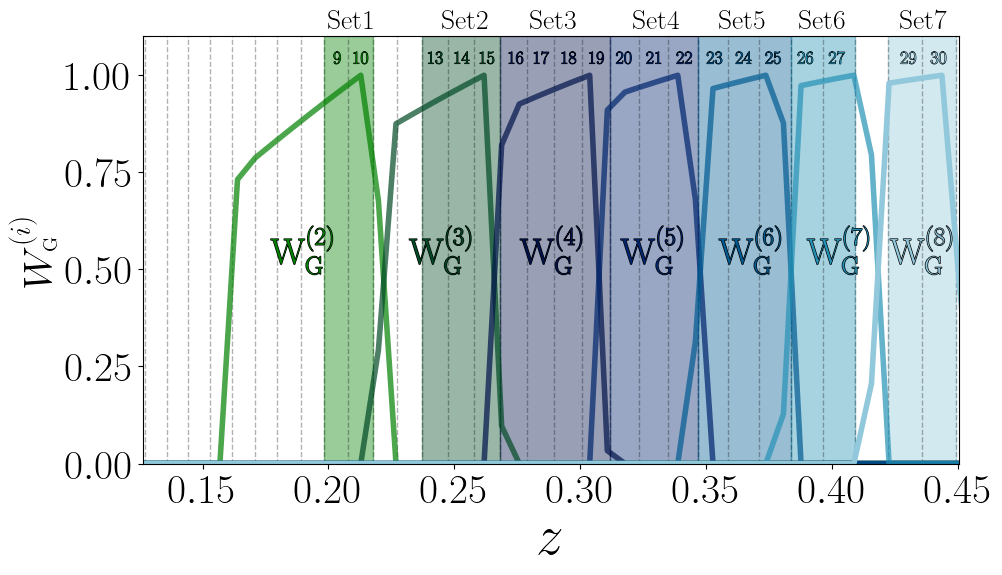

In [110]:
fig, ax   = plt.subplots(nrows=1, ncols=1)
plt.subplots_adjust(top=1,right=1.4, wspace=0.02,)     
############################################################
bins = [1,2,3,4,5,6,7]
n,N  = len(bins),len(bins)
c    = np.arange(1., n + 1)
norm = mpl.colors.BoundaryNorm(np.arange(1, N+2,1),N)
cmap = plt.get_cmap("ocean", N+1)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
############################################################
for i,iz in enumerate(z_lowz):
    ax.axvline(x=iz, c='black',ls='dashed', lw=1, alpha=0.3)

for i,gbin in enumerate(bins):
    zg = W_f2_40['z'][gbin]
    Wg = W_f2_40['W'][gbin]
    x=zg
    y=Wg
    y=y/y.max()
    if gbin==7:
        ax.plot(x, y, c=cmap(i), label=None,lw=4, ls='solid' , alpha=1.0)   
    else:
        ax.plot(x, y, c=cmap(i), label=None,lw=4, ls='solid' , alpha=0.7)   
##
##
for ic,i  in enumerate(bins):#Whis.keys()
    whi = dcopy( Whis[i] )
    zhi = dcopy( zhis[i] )
    for j in range(whi.shape[0]):
        x = zhi[j]
        y = whi[j]
        y=y/y.max()
        #ax.plot(x, y, c=cmap2(i), label=None,lw=2, ls='solid' , alpha=1.00)   
    x = zhi.flatten()
    if ic==7:
        ax.axvspan(x.min(), x.max(), alpha=1.0, color=cmap(ic))
    else:
        ax.axvspan(x.min(), x.max(), alpha=0.4, color=cmap(ic))
############################################################
ax.set_xlabel(r"$z$"                      , fontsize =40)
ax.set_ylabel(r"$W_{\textrm{\Large G}}^{(i)}$", fontsize =30)    
ax.tick_params(axis='both', which='major' , labelsize=30)
ax.set_xlim(z_lowz.min()-0.001,z_lowz.max()+0.001)
ax.set_ylim(-0.0001,1.1)
ax.set_xticks([0.15, 0.2, 0.25, 0.3, 0.35, 0.40, 0.45])
###########################################################
if 0:
    cticks = np.arange(1, N+1,1)#np.linspace(1, len(c)+1, len(c), dtype=np.int8)
    cticks = np.linspace(cticks.min(), cticks.max(),n, dtype=np.int16)
    cbar=fig.colorbar(sm, ax=ax, pad=0.02, aspect=40, ticks=cticks+0.5, alpha=0.7)
    cbar.set_label(label=r'$i\textrm{-bin}$',size=30)#,weight='bold')
    cticks = np.array([r'${}$'.format(i) for i in cticks+1])
    cbar.ax.set_yticklabels(cticks)
    cbar.ax.tick_params(labelsize=25, pad=10)
###########################################################
plot_filter_texts(ax, cmap_=cmap, index_start=0, cweight_2='heavy', add_text_outline2=True, text_outline_lw=0.7)

xrange = [0.177, 0.232, 0.276, 0.316, 0.355, 0.390, 0.423]
for i in [0,1,2,3,4,5,6]:
    ax.text(x=xrange[i], y=0.55, s=r'$\mathrm{W}_{\rm G}^{(' + str(i+2) + r')}$',fontsize=26,
            family='serif',color=cmap(i),weight='heavy',ha='left',va='center',
            path_effects=[pe.withStroke(linewidth=1.0, foreground='black')],
            zorder=20)
###########################################################
pathname = "/data/AMARINS/LSSxHI-CODES/images/{}_{}_{}_v2.pdf".format( 'galaxy',"kernel", "4paper" )
plt.savefig(pathname, dpi=100, bbox_inches='tight');
print(pathname)
###########################################################
plt.show()

In [328]:
zhi = dcopy( zhis[1] )
zhi.flatten().min(), zhi.flatten().max(), 0.198-0.217

(0.1983175633588303, 0.21749064437257146)